# Dynamic Neural Networks for Medical X-ray Segmentation (PS2)
**Early-exit U-Net with budget-aware routing, evaluated on FracAtlas (main) and Kvasir-SEG (generalization).**
Roll no. 2402CS12 | Run on Kaggle: Accelerator = GPU (T4/P100), Internet = On. Attach your private FracAtlas dataset with *Add Data*.

**Pipeline:** setup -> data + EDA -> metrics (Dice, IoU, precision, recall, pixel accuracy, HD95) -> baselines (U-Net scratch, U-Net ResNet34, DeepLabV3+, SegFormer) -> proposed dynamic model (multi-exit + self-distillation + Focal-Tversky) -> exit policies (BranchyNet-style confidence, agreement, supervised router, Gumbel gates) -> complexity (params, GMACs, latency, throughput, memory) -> ablations -> second dataset + official split -> figures and final table.

**Reproducibility:** fixed seeds (42, 43, 44); every run is cached as JSON in `WORK/results`, so if the Kaggle session stops you can re-run all cells and finished runs are skipped. Set `SMOKE = True` once to test the whole notebook in a few minutes.
Approximate GPU time with defaults: 4-5 h (set `SEEDS = [42]` to cut it to ~1.5 h).

In [1]:
!pip -q install segmentation-models-pytorch albumentations pycocotools kagglehub scipy pandas

In [2]:
import os, glob, json, random, time, copy, math, warnings
from pathlib import Path
import numpy as np, pandas as pd, cv2, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from sklearn.model_selection import train_test_split
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
warnings.filterwarnings("ignore")

# ------------------------------ CONFIG ------------------------------
SMOKE   = False            # True = 2 epochs, 1 seed, to test the pipeline end to end
SEEDS   = [42, 43, 44]
EPOCHS  = 80
LR      = 1e-4
IMG     = 256
BATCH   = 16
RUN_SCRATCH, RUN_DEEPLAB, RUN_SEGFORMER = True, True, True
RUN_ABLATION_LOSS = True    # Focal-Tversky ablation
RUN_GUMBEL        = True    # learned Gumbel-Softmax gates (negative-result ablation)
RUN_OFFICIAL_SPLIT = True   # FracAtlas official train/valid/test split
RUN_KVASIR        = True    # second dataset
KV_SEEDS = [42]
GUMBEL_EPOCHS, GUMBEL_LAMS = 40, [0.0, 0.5, 1.0]
KD_WEIGHT = 0.5             # self-distillation weight (exits 1,2 learn from exit 3)
if SMOKE:
    SEEDS, KV_SEEDS, EPOCHS, GUMBEL_EPOCHS, GUMBEL_LAMS = [42], [42], 2, 2, [0.5]
ALLOW_NO_PRETRAIN = SMOKE   # in a real run a failed weight download must stop the notebook
# ---------------------------------------------------------------------

WORK = Path("/kaggle/working") if Path("/kaggle").exists() else Path("./work")
(WORK / "results").mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    os.environ["PYTHONHASHSEED"] = str(s)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

def cached(name, job):
    # Run job() once, store the JSON-able result; later calls load it from disk.
    p = WORK / "results" / f"{name}.json"
    if p.exists(): return json.load(open(p))
    out = job(); json.dump(out, open(p, "w")); return out

ROWS = []   # one dict per (dataset, model, seed): all metrics + complexity

Device: cuda Tesla T4


## 1. Data
**FracAtlas** (Abedeen et al., *Scientific Data* 2023, CC-BY 4.0): only images with at least one fracture mask are used (COCO polygons merged into one binary mask), CLAHE, resize to 256x256 (area interpolation, 0.25 threshold so thin fracture lines survive).
**Kvasir-SEG** (polyp segmentation, RGB) is the second dataset for the generalization check.

In [3]:
COCO_NAME = "COCO_fracture_masks.json"
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}

def pick_root(coco_file):
    for par in coco_file.parents:
        if (par / "images").is_dir(): return par
    return coco_file.parents[2] if len(coco_file.parents) > 2 else coco_file.parent

def find_coco(base="/kaggle/input"):
    base = Path(base); hits = sorted(base.rglob(COCO_NAME))
    if not hits:
        for p in sorted(base.rglob("*.json")):
            try:
                d = json.load(open(p))
                if isinstance(d, dict) and d.get("images") and any(a.get("segmentation") for a in d.get("annotations", [])):
                    hits.append(p); break
            except Exception: pass
    return (hits[0], pick_root(hits[0])) if hits else (None, None)

def index_images(root):
    idx = {}
    for p in Path(root).rglob("*"):
        if p.suffix.lower() in IMG_EXT: idx.setdefault(p.name, p)
    return idx

def resize_mask(m, size):
    return (cv2.resize((m * 255).astype(np.uint8), (size, size), interpolation=cv2.INTER_AREA) >= 64).astype(np.uint8)

class Bundle:
    # images X (N,H,W) gray or (N,H,W,3) RGB, binary masks Y (N,H,W), file names, and a split dict of index arrays
    def __init__(self, X, Y, names, split, name, gray):
        self.X, self.Y, self.names, self.split, self.name, self.gray = X, Y, names, split, name, gray
    def with_split(self, split, name): return Bundle(self.X, self.Y, self.names, split, name, self.gray)

def random_split(n, seed=42):
    idx = np.arange(n)
    tr, te = train_test_split(idx, test_size=0.10, random_state=seed)
    tr, va = train_test_split(tr, test_size=1 / 9, random_state=seed)
    return {"train": tr, "val": va, "test": te}

def load_fracatlas():
    from pycocotools.coco import COCO
    coco_path, root = find_coco()
    assert coco_path is not None, "COCO mask file not found in /kaggle/input (attach the FracAtlas dataset)"
    coco = COCO(str(coco_path)); img_index = index_images(root)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    X, Y, names = [], [], []
    for info in coco.loadImgs(coco.getImgIds()):
        m = np.zeros((info["height"], info["width"]), np.uint8)
        for ann in coco.loadAnns(coco.getAnnIds(imgIds=info["id"], iscrowd=None)):
            if ann.get("segmentation"): m |= coco.annToMask(ann).astype(np.uint8)
        if m.sum() == 0: continue
        p = img_index.get(Path(info["file_name"]).name)
        g = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE) if p is not None else None
        if g is None: continue
        if g.shape != m.shape: m = cv2.resize(m, (g.shape[1], g.shape[0]), interpolation=cv2.INTER_NEAREST)
        X.append(cv2.resize(clahe.apply(g), (IMG, IMG), interpolation=cv2.INTER_AREA))
        Y.append(resize_mask(m, IMG)); names.append(info["file_name"])
    X, Y = np.stack(X), np.stack(Y)
    return Bundle(X, Y, names, random_split(len(X)), "FracAtlas", gray=True), root

def official_split(b, root):
    # FracAtlas ships Utilities/Fracture Split/{train,valid,test}.csv; images not listed go to train.
    sp = Path(root) / "Utilities" / "Fracture Split"
    stems = {Path(n).stem: i for i, n in enumerate(b.names)}
    out = {}
    for key, f in [("train", "train.csv"), ("val", "valid.csv"), ("test", "test.csv")]:
        df = pd.read_csv(sp / f); ids = []
        for col in df.columns:
            vals = df[col].astype(str).map(lambda s: Path(s).stem)
            hit = [stems[v] for v in vals if v in stems]
            if len(hit) > len(ids): ids = hit
        out[key] = np.array(sorted(set(ids)))
    used = set(np.concatenate(list(out.values())).tolist())
    out["train"] = np.array(sorted(set(out["train"].tolist()) | (set(range(len(b.names))) - used)))
    return out

def load_kvasir():
    base = Path("/kaggle/input")
    def find():
        for d in base.rglob("images"):
            if d.is_dir() and (d.parent / "masks").is_dir(): return d.parent
        return None
    root = find()
    if root is None:
        import kagglehub
        base = Path(kagglehub.dataset_download("debeshjha1/kvasirseg")); root = find()
    assert root is not None, "Kvasir-SEG not found: attach 'debeshjha1/kvasirseg' with Add Data"
    X, Y, names = [], [], []
    for p in sorted((root / "images").glob("*")):
        mp = root / "masks" / p.name
        if not mp.exists(): continue
        im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB); m = cv2.imread(str(mp), cv2.IMREAD_GRAYSCALE)
        X.append(cv2.resize(im, (IMG, IMG), interpolation=cv2.INTER_AREA))
        Y.append(resize_mask((m > 127).astype(np.uint8), IMG)); names.append(p.name)
    X, Y = np.stack(X), np.stack(Y)
    return Bundle(X, Y, names, random_split(len(X)), "Kvasir-SEG", gray=False)

FA, FA_ROOT = load_fracatlas()
print(f"FracAtlas fractured images kept: {len(FA.X)} | split sizes:", {k: len(v) for k, v in FA.split.items()})
json.dump({k: [FA.names[i] for i in v] for k, v in FA.split.items()}, open(WORK / "split_seed42.json", "w"), indent=1)

loading annotations into memory...
Done (t=0.77s)
creating index...
index created!
FracAtlas fractured images kept: 719 | split sizes: {'train': 575, 'val': 72, 'test': 72}


Mask area fraction: mean=0.0049 median=0.0035 min=0.00064 max=0.0295
Pixel class balance: fracture 0.49% vs background 99.51%
Image intensity after CLAHE: mean=64.1, std=54.2


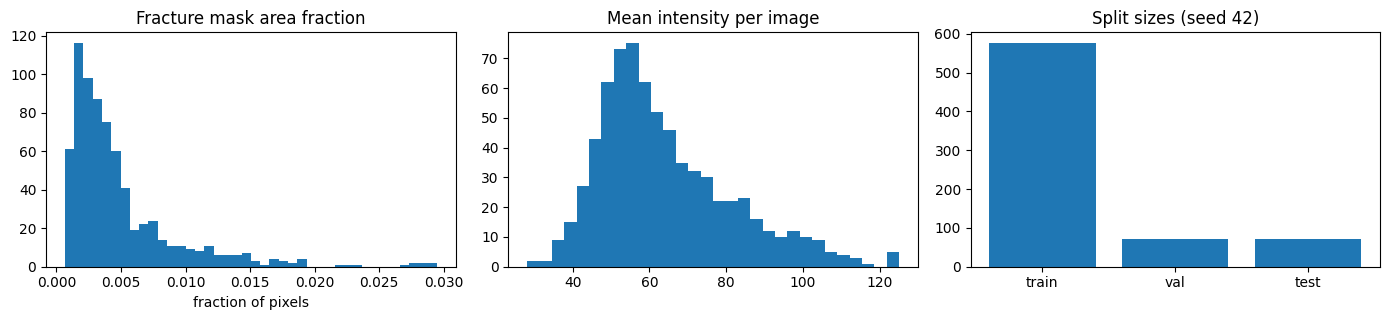

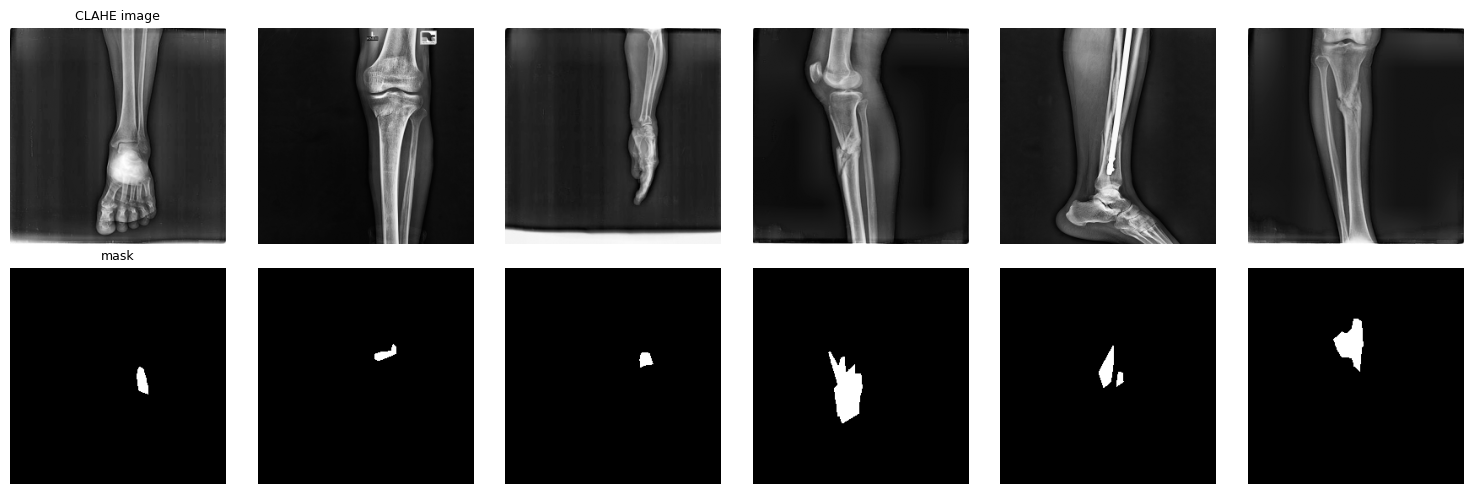

In [4]:
# ---- EDA: mask area, original sizes, intensity statistics, sample images ----
area = FA.Y.reshape(len(FA.Y), -1).mean(1)
print(f"Mask area fraction: mean={area.mean():.4f} median={np.median(area):.4f} min={area.min():.5f} max={area.max():.4f}")
print(f"Pixel class balance: fracture {FA.Y.mean()*100:.2f}% vs background {100-FA.Y.mean()*100:.2f}%")
print(f"Image intensity after CLAHE: mean={FA.X.mean():.1f}, std={FA.X.std():.1f}")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.3))
ax[0].hist(area, bins=40); ax[0].set_title("Fracture mask area fraction"); ax[0].set_xlabel("fraction of pixels")
ax[1].hist(FA.X.reshape(len(FA.X), -1).mean(1), bins=30); ax[1].set_title("Mean intensity per image")
ax[2].bar(["train", "val", "test"], [len(FA.split[k]) for k in ["train", "val", "test"]]); ax[2].set_title("Split sizes (seed 42)")
plt.tight_layout(); plt.savefig(WORK / "fig_eda.png", dpi=200); plt.show()
pick = np.random.RandomState(42).choice(len(FA.X), 6, replace=False)
fig, axs = plt.subplots(2, 6, figsize=(15, 5))
for c, i in enumerate(pick):
    axs[0, c].imshow(FA.X[i], cmap="gray"); axs[0, c].axis("off"); axs[1, c].imshow(FA.Y[i], cmap="gray"); axs[1, c].axis("off")
axs[0, 0].set_title("CLAHE image", fontsize=9); axs[1, 0].set_title("mask", fontsize=9)
plt.tight_layout(); plt.savefig(WORK / "fig_samples.png", dpi=200); plt.show()

In [5]:
# ---- loaders and augmentation ----
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
train_tf = A.Compose([A.HorizontalFlip(p=0.5), A.Rotate(limit=15, p=0.5),
                      A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
                      A.Normalize(mean=MEAN, std=STD), ToTensorV2()])
eval_tf = A.Compose([A.Normalize(mean=MEAN, std=STD), ToTensorV2()])

class SegDS(torch.utils.data.Dataset):
    def __init__(self, b, ids, tf): self.b, self.ids, self.tf = b, ids, tf
    def __len__(self): return len(self.ids)
    def __getitem__(self, k):
        i = self.ids[k]; img = self.b.X[i]
        if self.b.gray: img = np.repeat(img[..., None], 3, axis=2)
        out = self.tf(image=img, mask=self.b.Y[i])
        return out["image"], out["mask"].unsqueeze(0).float()

def seed_worker(_):
    s = torch.initial_seed() % 2 ** 32; np.random.seed(s); random.seed(s)

def make_dl(b, key, train, seed=42, bs=BATCH):
    g = torch.Generator(); g.manual_seed(seed)
    return torch.utils.data.DataLoader(SegDS(b, b.split[key], train_tf if train else eval_tf), batch_size=bs,
                                       shuffle=train, num_workers=2, worker_init_fn=seed_worker, generator=g)
xb, yb = next(iter(make_dl(FA, "train", True)))
print("batch:", tuple(xb.shape), tuple(yb.shape), "| mask values:", yb.unique().tolist())

batch: (16, 3, 256, 256) (16, 1, 256, 256) | mask values: [0.0, 1.0]


## 2. Losses and metrics
Per-pixel $p=\sigma(z)$, ground truth $y$. $TP=\sum py$, $FP=\sum p(1-y)$, $FN=\sum(1-p)y$.

- **BCE + Dice:** $\mathcal L_{seg}=\mathrm{BCE}(z,y)+\bigl(1-\tfrac{2TP+\epsilon}{2TP+FP+FN+\epsilon}\bigr)$
- **Focal-Tversky (class imbalance, thin lines):** $\mathcal L_{FT}=\mathrm{BCE}(z,y)+\bigl(1-TI\bigr)^{\gamma}$, $TI=\frac{TP+\epsilon}{TP+\alpha FN+\beta FP+\epsilon}$, with $\alpha=0.7,\beta=0.3,\gamma=0.75$ (false negatives cost more than false positives).
- **Metrics (per image, then averaged):** Dice, IoU, precision, recall, pixel accuracy, **HD95** = 95th percentile of the union of the two directed boundary distances (pixels at 256x256). Empty prediction or empty ground truth (not both) is scored with the image diagonal (362 px); both empty = 0.
- The binarisation threshold is **tuned on the validation split only** (grid 0.2-0.6) and applied to test; Dice at 0.5 is also stored.

In [6]:
def dice_loss(logits, y, eps=1.0):
    p = torch.sigmoid(logits); d = (1, 2, 3)
    return 1 - ((2 * (p * y).sum(d) + eps) / (p.sum(d) + y.sum(d) + eps)).mean()

def focal_tversky(logits, y, a=0.7, b=0.3, g=0.75, eps=1.0):
    p = torch.sigmoid(logits); d = (1, 2, 3)
    tp = (p * y).sum(d); fn = ((1 - p) * y).sum(d); fp = (p * (1 - y)).sum(d)
    return ((1 - (tp + eps) / (tp + a * fn + b * fp + eps)) ** g).mean()

_bce = nn.BCEWithLogitsLoss()
def seg_loss(logits, y, kind="bce_dice"):
    return _bce(logits, y) + (focal_tversky(logits, y) if kind == "bce_ft" else dice_loss(logits, y))

@torch.no_grad()
def per_image(logits, y, thr=0.5, eps=1e-7):
    p = (torch.sigmoid(logits) > thr).float(); d = (1, 2, 3); n = p[0].numel()
    tp = (p * y).sum(d); fp = (p * (1 - y)).sum(d); fn = ((1 - p) * y).sum(d); tn = n - tp - fp - fn
    return {"dice": (2 * tp + eps) / (2 * tp + fp + fn + eps), "iou": (tp + eps) / (tp + fp + fn + eps),
            "prec": (tp + eps) / (tp + fp + eps), "rec": (tp + eps) / (tp + fn + eps), "pixacc": (tp + tn) / n}

def hd95_one(pred, gt):
    diag = float(np.hypot(*pred.shape))
    if not pred.any() and not gt.any(): return 0.0
    if not pred.any() or not gt.any(): return diag
    sp, sg = pred ^ ndi.binary_erosion(pred), gt ^ ndi.binary_erosion(gt)
    if not sp.any(): sp = pred
    if not sg.any(): sg = gt
    dg, dp = ndi.distance_transform_edt(~gt), ndi.distance_transform_edt(~pred)
    return float(np.percentile(np.concatenate([dg[sp], dp[sg]]), 95))

def evaluate(logits, y, thr=0.5):
    # logits, y: CPU tensors (N,1,H,W). Returns (mean metrics, per-image arrays)
    per = {k: v.numpy() for k, v in per_image(logits, y, thr).items()}
    pred = (torch.sigmoid(logits) > thr)[:, 0].numpy(); gt = (y[:, 0] > 0.5).numpy()
    per["hd95"] = np.array([hd95_one(p, g) for p, g in zip(pred, gt)])
    return {k: float(v.mean()) for k, v in per.items()}, per

def tune_thr(logits, y, grid=(0.2, 0.3, 0.4, 0.5, 0.6)):
    return max(grid, key=lambda t: per_image(logits, y, t)["dice"].mean().item())

@torch.no_grad()
def collect(fn, dl):
    # fn(x) -> list of logits tensors (one per output). Returns ([cpu logits per output], cpu y)
    outs, ys = None, []
    for x, y in dl:
        o = fn(x.to(DEVICE)); o = [t.cpu() for t in o]
        outs = [[t] for t in o] if outs is None else [a + [t] for a, t in zip(outs, o)]
        ys.append(y)
    return [torch.cat(a) for a in outs], torch.cat(ys)

## 3. Complexity profiling (parameters, GMACs, latency, throughput, memory)
MACs are counted with `torch.utils.flop_counter` (convolutions **and** matrix multiplies, so attention in SegFormer is included; MACs = FLOPs / 2). Latency: batch 1 and batch 16 (per image), after warm-up, with CUDA synchronisation. Throughput = images/s at batch 16. Memory = peak allocated GPU memory for one batch-16 forward pass.

In [7]:
def macs_of(fn, x):
    from torch.utils.flop_counter import FlopCounterMode
    with torch.no_grad(), FlopCounterMode(display=False) as fc: fn(x)
    return fc.get_total_flops() / 2

def _sync():
    if DEVICE.type == "cuda": torch.cuda.synchronize()

@torch.no_grad()
def profile(fn, module, size=IMG, warm=10, reps=30):
    # fn(x) -> output; module = nn.Module used for the parameter count
    module.eval(); x1 = torch.randn(1, 3, size, size, device=DEVICE); x16 = torch.randn(16, 3, size, size, device=DEVICE)
    macs = macs_of(fn, x1)
    def tm(x):
        for _ in range(warm): fn(x)
        _sync(); t = time.perf_counter()
        for _ in range(reps): fn(x)
        _sync(); return (time.perf_counter() - t) / reps * 1000
    b1, b16 = tm(x1), tm(x16) / 16
    mem = None
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats(); fn(x16); _sync(); mem = torch.cuda.max_memory_allocated() / 2 ** 20
    return {"params_M": sum(p.numel() for p in module.parameters()) / 1e6, "gmacs": macs / 1e9,
            "ms_b1": b1, "ms_b16_per_img": b16, "img_per_s": 1000 / b16, "mem_mb": mem}

## 4. Models
**Static baselines:** U-Net written from scratch; U-Net, DeepLabV3+ (ResNet34 encoders, ImageNet weights) and **SegFormer-B0** (transformer, `mit_b0` encoder) from `segmentation_models_pytorch`.

**Proposed dynamic model (`EarlyExitUNet`):** ResNet34 encoder, two light FPN exit heads (after layer2 and layer3) and the full U-Net decoder as the last exit. Deep supervision trains all exits; **self-distillation** makes the cheap exits imitate the full exit.

$$\mathcal L=\sum_{k=1}^{3} w_k\,\mathcal L_{seg}(z_k,y)\;+\;\lambda_{kd}\sum_{k=1}^{2}\mathrm{BCE}\bigl(z_k,\sigma(z_3)\bigr)_{\text{stop-grad on }z_3},\qquad w=(0.5,0.5,1)$$

Exit costs $C_k$ are measured MACs normalised by the full path ($C_3=1$).

In [8]:
class DoubleConv(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.block = nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True),
                                   nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True))
    def forward(self, x): return self.block(x)

class UNet(nn.Module):
    def __init__(self, in_ch=3, base=32):
        super().__init__(); c = [base * 2 ** k for k in range(5)]
        self.enc = nn.ModuleList([DoubleConv(in_ch, c[0])] + [DoubleConv(c[k], c[k + 1]) for k in range(4)])
        self.pool = nn.MaxPool2d(2)
        self.up = nn.ModuleList([nn.ConvTranspose2d(c[k + 1], c[k], 2, stride=2) for k in reversed(range(4))])
        self.dec = nn.ModuleList([DoubleConv(2 * c[k], c[k]) for k in reversed(range(4))])
        self.out = nn.Conv2d(c[0], 1, 1)
    def forward(self, x):
        skips = []
        for k, e in enumerate(self.enc):
            x = e(x)
            if k < 4: skips.append(x); x = self.pool(x)
        for up, dec, s in zip(self.up, self.dec, reversed(skips)): x = dec(torch.cat([s, up(x)], 1))
        return self.out(x)

def _smp(ctor, enc, **kw):
    try: return ctor(enc, encoder_weights="imagenet", in_channels=3, classes=1, **kw)
    except Exception as e:
        if not ALLOW_NO_PRETRAIN: raise RuntimeError(f"pretrained weights for {enc} could not be loaded (Internet on?): {e}")
        print("WARNING (smoke test only): no pretrained weights for", enc); return ctor(enc, encoder_weights=None, in_channels=3, classes=1, **kw)

ARCHS = {"unet_scratch": lambda: UNet(),
         "unet_r34": lambda: _smp(smp.Unet, "resnet34"),
         "deeplabv3p_r34": lambda: _smp(smp.DeepLabV3Plus, "resnet34"),
         "segformer_b0": lambda: _smp(smp.Segformer, "mit_b0")}
NAMES = {"unet_scratch": "U-Net (scratch)", "unet_r34": "U-Net ResNet34", "deeplabv3p_r34": "DeepLabV3+ ResNet34",
         "segformer_b0": "SegFormer-B0 (transformer)"}

In [9]:
import torchvision
def make_resnet34():
    try: return torchvision.models.resnet34(weights=torchvision.models.ResNet34_Weights.IMAGENET1K_V1)
    except Exception as e:
        if not ALLOW_NO_PRETRAIN: raise RuntimeError(f"Could not load pretrained ResNet34 (is Internet on?): {e}")
        print("WARNING (smoke test only): ResNet34 without pretrained weights"); return torchvision.models.resnet34(weights=None)

class LightHead(nn.Module):                      # small FPN-style exit head: deep -> shallow features
    def __init__(self, chs, mid=32):
        super().__init__()
        self.lat = nn.ModuleList([nn.Conv2d(c, mid, 1) for c in chs])
        self.out = nn.Sequential(nn.Conv2d(mid, 16, 3, padding=1), nn.ReLU(True), nn.Conv2d(16, 1, 1))
    def forward(self, feats):
        p = self.lat[0](feats[0])
        for lat, f in zip(self.lat[1:], feats[1:]):
            p = F.interpolate(p, size=f.shape[-2:], mode="bilinear", align_corners=False) + lat(f)
        return F.interpolate(self.out(p), scale_factor=2, mode="bilinear", align_corners=False)

class Up(nn.Module):
    def __init__(self, cin, cskip, cout):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(cin + cskip, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(True),
                                  nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(True))
    def forward(self, x, skip): return self.conv(torch.cat([F.interpolate(x, size=skip.shape[-2:], mode="nearest"), skip], 1))

def uncertainty(logit):                         # entropy and max confidence of an exit prediction
    p = torch.sigmoid(logit.detach())
    ent = -(p * torch.log(p + 1e-6) + (1 - p) * torch.log(1 - p + 1e-6)).mean((1, 2, 3)) * 10
    return torch.stack([ent, p.amax(dim=(1, 2, 3))], 1)

class Gate(nn.Module):                           # logits: index 0 = exit here, 1 = continue
    def __init__(self, c, use_unc=True):
        super().__init__(); self.use_unc = use_unc
        self.net = nn.Sequential(nn.Linear(c + 2, 32), nn.ReLU(True), nn.Linear(32, 2))
        with torch.no_grad(): self.net[2].bias.copy_(torch.tensor([-1.0, 1.0]))
    def forward(self, pooled, logit):
        unc = uncertainty(logit) if self.use_unc else torch.zeros(len(pooled), 2, device=pooled.device)
        return self.net(torch.cat([pooled.detach(), unc], 1))

class EarlyExitUNet(nn.Module):
    def __init__(self):
        super().__init__(); r = make_resnet34()
        self.s1 = nn.Sequential(r.conv1, r.bn1, r.relu); self.s2 = nn.Sequential(r.maxpool, r.layer1)
        self.s3, self.s4, self.s5 = r.layer2, r.layer3, r.layer4
        self.head1, self.head2 = LightHead([128, 64, 64]), LightHead([256, 128, 64, 64])
        self.gate1, self.gate2 = Gate(128), Gate(256)
        self.d4, self.d3, self.d2, self.d1 = Up(512, 256, 128), Up(128, 128, 64), Up(64, 64, 48), Up(48, 64, 32)
        self.final = nn.Sequential(nn.Conv2d(32, 16, 3, padding=1), nn.ReLU(True), nn.Conv2d(16, 1, 1))
        self.F = [1.0, 1.0, 1.0]
    def _dec(self, f1, f2, f3, f4, f5):
        d = self.d1(self.d2(self.d3(self.d4(f5, f4), f3), f2), f1)
        return F.interpolate(self.final(d), scale_factor=2, mode="bilinear", align_corners=False)
    def forward_all(self, x):                    # training / offline analysis: every exit is computed
        f1 = self.s1(x); f2 = self.s2(f1); f3 = self.s3(f2)
        l1 = self.head1([f3, f2, f1]); f4 = self.s4(f3); l2 = self.head2([f4, f3, f2, f1])
        l3 = self._dec(f1, f2, f3, f4, self.s5(f4)); p3, p4 = f3.mean((2, 3)), f4.mean((2, 3))
        return {"logits": [l1, l2, l3], "pooled": [p3, p4], "gates": [self.gate1(p3, l1), self.gate2(p4, l2)]}
    def forward_upto(self, x, k):                # inference path that stops at exit k (no gates)
        f1 = self.s1(x); f2 = self.s2(f1); f3 = self.s3(f2); l1 = self.head1([f3, f2, f1])
        if k == 1: return l1
        f4 = self.s4(f3); l2 = self.head2([f4, f3, f2, f1])
        if k == 2: return l2
        return self._dec(f1, f2, f3, f4, self.s5(f4))
    @torch.no_grad()
    def forward_dynamic(self, x, stop1, stop2):  # true conditional inference for a batch of 1
        f1 = self.s1(x); f2 = self.s2(f1); f3 = self.s3(f2); l1 = self.head1([f3, f2, f1])
        if stop1(l1): return l1, 0
        f4 = self.s4(f3); l2 = self.head2([f4, f3, f2, f1])
        if stop2(l2, l1): return l2, 1
        return self._dec(f1, f2, f3, f4, self.s5(f4)), 2

def new_me():
    m = EarlyExitUNet().to(DEVICE); m.eval()
    m.F = [macs_of(lambda x, k=k: m.forward_upto(x, k), torch.zeros(1, 3, IMG, IMG, device=DEVICE)) for k in (1, 2, 3)]
    return m
_m = new_me(); print("MACs to exit 1/2/3 (G):", [round(f / 1e9, 2) for f in _m.F], "| ratios:", [round(f / _m.F[2], 3) for f in _m.F],
                      "| params (M):", round(sum(p.numel() for p in _m.parameters()) / 1e6, 2)); del _m

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 197MB/s]


MACs to exit 1/2/3 (G): [2.32, 4.19, 6.55] | ratios: [0.355, 0.64, 1.0] | params (M): 22.67


## 5. Training and evaluation helpers
Every run: AdamW (lr 1e-4, wd 1e-4), cosine schedule, best epoch chosen on validation Dice, test evaluated once with the validation-tuned threshold. Logits are saved so policies, bootstrap and figures need no retraining.

In [10]:
def fit(model, b, seed, epochs, loss_fn, score_fn, ckpt, lr=LR):
    tr, va = make_dl(b, "train", True, seed), make_dl(b, "val", False, seed)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    best, hist = -1.0, {"train_loss": [], "val_score": []}
    for ep in range(epochs):
        model.train(); tot = n = 0
        for x, y in tr:
            x, y = x.to(DEVICE), y.to(DEVICE); loss = loss_fn(model, x, y)
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(x); n += len(x)
        sch.step(); model.eval(); sc = score_fn(model, va)
        hist["train_loss"].append(tot / n); hist["val_score"].append(sc)
        if sc > best: best = sc; torch.save(model.state_dict(), ckpt)
        if (ep + 1) % 10 == 0 or ep == epochs - 1: print(f"  ep {ep+1:3d}/{epochs} loss {tot/n:.4f} val {sc:.4f} (best {best:.4f})")
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE)); model.eval()
    return hist, best

@torch.no_grad()
def val_dice_static(model, dl):
    return float(np.mean(np.concatenate([per_image(model(x.to(DEVICE)), y.to(DEVICE))["dice"].cpu().numpy() for x, y in dl])))

@torch.no_grad()
def val_dice_me(model, dl):    # mean Dice over the three exits
    ds = [[] for _ in range(3)]
    for x, y in dl:
        for k, l in enumerate(model.forward_all(x.to(DEVICE))["logits"]): ds[k].append(per_image(l, y.to(DEVICE))["dice"].cpu().numpy())
    return float(np.mean([np.concatenate(d).mean() for d in ds]))

def save_logits(b, tag, seed, val, test, vy, ty):
    torch.save({"val": [t.half() for t in val], "test": [t.half() for t in test], "vy": vy.bool(), "ty": ty.bool()},
               WORK / f"logits_{b.name}_{tag}_s{seed}.pt")
def load_logits(b, tag, seed):
    d = torch.load(WORK / f"logits_{b.name}_{tag}_s{seed}.pt")
    return [t.float() for t in d["val"]], [t.float() for t in d["test"]], d["vy"].float(), d["ty"].float()

def make_row(b, name, seed, vl, vy, tl, ty, prof, extra=None):
    thr = tune_thr(vl, vy); m, per = evaluate(tl, ty, thr); m05 = per_image(tl, ty, 0.5)["dice"].mean().item()
    val_dice = per_image(vl, vy, thr)["dice"].mean().item()
    row = {"dataset": b.name, "model": name, "seed": seed, "thr": thr, "val_dice": val_dice, "dice_thr05": m05, **m, **prof, **(extra or {})}
    return row, per["dice"].tolist()

def run_static(arch, seed, b, tag, loss_kind="bce_dice", epochs=None):
    epochs = epochs or EPOCHS
    def job():
        print(f"[{b.name}] {tag} seed {seed}"); set_seed(seed); model = ARCHS[arch]().to(DEVICE)
        ck = WORK / f"ck_{b.name}_{tag}_s{seed}.pt"; t0 = time.time()
        hist, best = fit(model, b, seed, epochs, lambda m, x, y: seg_loss(m(x), y, loss_kind), val_dice_static, ck)
        fn = lambda x: [model(x)]
        vl, vy = collect(fn, make_dl(b, "val", False)); tl, ty = collect(fn, make_dl(b, "test", False))
        save_logits(b, tag, seed, vl, tl, vy, ty)
        row, per = make_row(b, tag, seed, vl[0], vy, tl[0], ty, profile(lambda x: model(x), model), {"train_min": (time.time() - t0) / 60})
        return {"rows": [row], "hist": hist, "per_dice": per}
    return cached(f"{b.name}_{tag}_s{seed}", job)

def me_loss(model, x, y, kd, loss_kind, W=(0.5, 0.5, 1.0)):
    L = model.forward_all(x)["logits"]; loss = sum(w * seg_loss(l, y, loss_kind) for w, l in zip(W, L))
    if kd > 0:
        t = torch.sigmoid(L[2]).detach(); loss = loss + kd * sum(_bce(L[k], t) for k in (0, 1))
    return loss

def run_me(seed, b, tag, kd=0.0, loss_kind="bce_dice", epochs=None):
    epochs = epochs or EPOCHS
    def job():
        print(f"[{b.name}] {tag} seed {seed} (kd={kd}, loss={loss_kind})"); set_seed(seed); model = new_me()
        ck = WORK / f"ck_{b.name}_{tag}_s{seed}.pt"; t0 = time.time()
        hist, best = fit(model, b, seed, epochs, lambda m, x, y: me_loss(m, x, y, kd, loss_kind), val_dice_me, ck)
        fn = lambda x: model.forward_all(x)["logits"]
        vl, vy = collect(fn, make_dl(b, "val", False)); tl, ty = collect(fn, make_dl(b, "test", False))
        save_logits(b, tag, seed, vl, tl, vy, ty); rows, pers = [], []
        for k in range(3):
            prof = profile(lambda x, k=k: model.forward_upto(x, k + 1), model)
            r, per = make_row(b, f"{tag}:exit{k+1}", seed, vl[k], vy, tl[k], ty, prof, {"exit": k + 1, "train_min": (time.time() - t0) / 60})
            rows.append(r); pers.append(per)
        return {"rows": rows, "hist": hist, "per_dice": pers, "F": model.F}
    return cached(f"{b.name}_{tag}_s{seed}", job)

def add(res): ROWS.extend(res["rows"]); return res

## 6. Main experiments on FracAtlas (random 80/10/10 split, seed 42)
Static baselines, then the dynamic model in three configurations (ablation): **deep supervision only** -> **+ self-distillation** -> **+ Focal-Tversky loss**. The static ResNet34 U-Net is also trained with Focal-Tversky so the loss gain is not credited to the dynamic part.

In [11]:
HIST = {}
for s in SEEDS:
    HIST[("unet_r34", s)] = add(run_static("unet_r34", s, FA, "unet_r34"))["hist"]
    if RUN_DEEPLAB:   add(run_static("deeplabv3p_r34", s, FA, "deeplabv3p_r34"))
    if RUN_SEGFORMER: add(run_static("segformer_b0", s, FA, "segformer_b0"))
    if RUN_SCRATCH:   add(run_static("unet_scratch", s, FA, "unet_scratch"))
    HIST[("me_ds", s)] = add(run_me(s, FA, "me_ds", kd=0.0))["hist"]
    HIST[("me_kd", s)] = add(run_me(s, FA, "me_kd", kd=KD_WEIGHT))["hist"]
    if RUN_ABLATION_LOSS:
        add(run_static("unet_r34", s, FA, "unet_r34_ft", loss_kind="bce_ft"))
        HIST[("me_kd_ft", s)] = add(run_me(s, FA, "me_kd_ft", kd=KD_WEIGHT, loss_kind="bce_ft"))["hist"]
DF = pd.DataFrame(ROWS); print(len(DF), "result rows")

[FracAtlas] unet_r34 seed 42


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

  ep  10/80 loss 1.1364 val 0.2689 (best 0.2689)
  ep  20/80 loss 0.9270 val 0.4391 (best 0.4391)
  ep  30/80 loss 0.6826 val 0.4792 (best 0.5069)
  ep  40/80 loss 0.4752 val 0.5335 (best 0.5345)
  ep  50/80 loss 0.3497 val 0.5105 (best 0.5431)
  ep  60/80 loss 0.2889 val 0.5004 (best 0.5438)
  ep  70/80 loss 0.2621 val 0.4994 (best 0.5438)
  ep  80/80 loss 0.2537 val 0.4965 (best 0.5438)
[FracAtlas] deeplabv3p_r34 seed 42
  ep  10/80 loss 1.0152 val 0.2015 (best 0.2264)
  ep  20/80 loss 0.7191 val 0.4475 (best 0.4475)
  ep  30/80 loss 0.4722 val 0.4727 (best 0.5256)
  ep  40/80 loss 0.3537 val 0.5385 (best 0.5385)
  ep  50/80 loss 0.2987 val 0.5310 (best 0.5385)
  ep  60/80 loss 0.2667 val 0.5432 (best 0.5497)
  ep  70/80 loss 0.2535 val 0.5394 (best 0.5497)
  ep  80/80 loss 0.2504 val 0.5393 (best 0.5497)
[FracAtlas] segformer_b0 seed 42


config.json:   0%|          | 0.00/135 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.3MB            

model.safetensors: downloading bytes:           |  0.00B            

  ep  10/80 loss 0.9502 val 0.2871 (best 0.2871)
  ep  20/80 loss 0.7254 val 0.4149 (best 0.4149)
  ep  30/80 loss 0.5743 val 0.4777 (best 0.4871)
  ep  40/80 loss 0.4870 val 0.5093 (best 0.5160)
  ep  50/80 loss 0.4336 val 0.5229 (best 0.5365)
  ep  60/80 loss 0.4086 val 0.5077 (best 0.5396)
  ep  70/80 loss 0.3930 val 0.5252 (best 0.5396)
  ep  80/80 loss 0.3928 val 0.5217 (best 0.5396)
[FracAtlas] unet_scratch seed 42
  ep  10/80 loss 1.3203 val 0.0000 (best 0.0179)
  ep  20/80 loss 1.2239 val 0.0000 (best 0.0179)
  ep  30/80 loss 1.1591 val 0.2297 (best 0.2297)
  ep  40/80 loss 1.1079 val 0.2942 (best 0.3156)
  ep  50/80 loss 1.0718 val 0.3546 (best 0.3546)
  ep  60/80 loss 1.0483 val 0.3635 (best 0.3805)
  ep  70/80 loss 1.0380 val 0.3745 (best 0.3805)
  ep  80/80 loss 1.0363 val 0.3740 (best 0.3805)
[FracAtlas] me_ds seed 42 (kd=0.0, loss=bce_dice)
  ep  10/80 loss 1.3937 val 0.3741 (best 0.4060)
  ep  20/80 loss 1.1182 val 0.4447 (best 0.4714)
  ep  30/80 loss 0.9652 val 0.4657 

In [12]:
# ---- model selection on VALIDATION: which dynamic configuration is "proposed"? ----
me_tags = [t for t in ["me_ds", "me_kd", "me_kd_ft"] if (DF.model == f"{t}:exit3").any()]
sel = {t: DF[(DF.dataset == "FracAtlas") & (DF.model == f"{t}:exit3")].val_dice.mean() for t in me_tags}
PROPOSED = max(sel, key=sel.get); print("mean val Dice of exit 3 per configuration:", {k: round(v, 4) for k, v in sel.items()}); print("PROPOSED =", PROPOSED)

mean val Dice of exit 3 per configuration: {'me_ds': np.float64(0.5477), 'me_kd': np.float64(0.5775), 'me_kd_ft': np.float64(0.5715)}
PROPOSED = me_kd


## 7. Dynamic exit policies (offline analysis on saved logits, then true conditional inference)
All policies decide **per image** which exit to use. Parameters are chosen on the **validation** split only; test is evaluated once. Policies are evaluated at threshold 0.5.

- **Fixed exits** (static truncation) and **chance routing** = random mixture of fixed exits at the same MACs (linear interpolation of fixed-exit Dice). A learned policy must beat this line to be worth its overhead.
- **BranchyNet-style confidence exit:** stop at exit $k$ if the *foreground confidence* $c(z)=\frac{\sum_{p>0.5}p}{\sum \mathbb 1[p>0.5]}\ge\tau_k$ (an empty prediction never exits).
- **Agreement exit:** stop at exit 2 if $\mathrm{Dice}(\hat y_1,\hat y_2)\ge\tau_2$ (exit 1 is already computed, so the cue is free).
- **Oracle router (upper bound, uses labels):** $k^*(x)=\arg\max_k\,[\mathrm{Dice}_k(x)-\alpha C_k]$.
- **Supervised router:** two small MLP gates on frozen pooled features + (entropy, confidence) of the exit prediction, trained to imitate the oracle on the training split.
- **Gumbel-Softmax gates:** learned end-to-end (section 8).
Constraint used to pick thresholds: minimise MACs subject to validation Dice $\ge$ validation Dice of exit 3 $-\delta$, for $\delta\in\{0.01,0.02,0.03\}$.

In [13]:
def cue_conf(l):
    p = torch.sigmoid(l); fg = (p > 0.5).float(); a = fg.flatten(1).sum(1)
    return torch.where(a > 0, (p * fg).flatten(1).sum(1) / a.clamp(min=1), torch.zeros_like(a))
def cue_agree(la, lb):
    a, b = (torch.sigmoid(la) > 0.5).float().flatten(1), (torch.sigmoid(lb) > 0.5).float().flatten(1)
    return (2 * (a * b).sum(1) + 1e-7) / (a.sum(1) + b.sum(1) + 1e-7)

def route(L, t1, t2, kind):
    s1 = cue_conf(L[0]) >= t1
    s2 = (cue_conf(L[1]) >= t2) if kind == "conf" else (cue_agree(L[0], L[1]) >= t2)
    idx = torch.full((len(s1),), 2); idx[s2] = 1; idx[s1] = 0; return idx

def eval_route(idx, L, Y, Fr):
    chosen = torch.stack(L, 1)[torch.arange(len(idx)), idx]; d = per_image(chosen, Y)["dice"]
    frac = [(idx == k).float().mean().item() for k in range(3)]
    return d.numpy(), frac, float(sum(f * c for f, c in zip(frac, Fr)))

GRID = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.98, 1.01]     # 1.01 = never stop here
TAG_CFG = {"me_ds": (0.0, "bce_dice"), "me_kd": (KD_WEIGHT, "bce_dice"), "me_kd_ft": (KD_WEIGHT, "bce_ft")}

def policy_analysis(b, tag, seed, deltas=(0.01, 0.02, 0.03)):
    res = cached(f"{b.name}_{tag}_s{seed}", lambda: None); Fm = res["F"]; Fr = [f / Fm[2] for f in Fm]
    vl, tl, vy, ty = load_logits(b, tag, seed)
    fixed_v = [per_image(l, vy)["dice"].mean().item() for l in vl]; fixed_t = [per_image(l, ty)["dice"].mean().item() for l in tl]
    mix = lambda r: float(np.interp(r, Fr, fixed_t))
    out = {"fixed_test": fixed_t, "fixed_val": fixed_v, "Fr": Fr, "gmacs_full": Fm[2] / 1e9, "policies": [], "pareto": []}
    for kind in ("conf", "agree"):
        pts = []
        for t1 in GRID:
            for t2 in GRID:
                dv, _, mv = eval_route(route(vl, t1, t2, kind), vl, vy, Fr)
                dt, ft, mt = eval_route(route(tl, t1, t2, kind), tl, ty, Fr)
                pts.append((t1, t2, dv.mean(), mv, dt.mean(), mt, ft)); out["pareto"].append((kind, dt.mean(), mt))
        for dl in deltas:
            ok = [p for p in pts if p[2] >= fixed_v[2] - dl]
            if not ok: out["policies"].append({"name": f"{kind}-exit (delta={dl})", "feasible": False}); continue
            p = min(ok, key=lambda q: (q[3], -q[2]))
            out["policies"].append({"name": f"{kind}-exit (delta={dl})", "feasible": True, "t1": p[0], "t2": p[1], "kind": kind,
                                    "dice": p[4], "macs_ratio": p[5], "exits": p[6], "chance_dice": mix(p[5]), "gain_vs_chance": p[4] - mix(p[5])})
    # oracle (labels used: upper bound)
    dt3 = np.stack([per_image(l, ty)["dice"].numpy() for l in tl], 1)
    for a in (0.0, 0.05, 0.10, 0.20):
        k = np.argmax(dt3 - a * np.array(Fr), 1); d = dt3[np.arange(len(k)), k]; r = float(np.mean(np.array(Fr)[k]))
        out["policies"].append({"name": f"oracle (alpha={a})", "feasible": True, "dice": float(d.mean()), "macs_ratio": r,
                                "exits": [float((k == j).mean()) for j in range(3)], "chance_dice": mix(r), "gain_vs_chance": float(d.mean()) - mix(r)})
    return out

POL = {}
for s in SEEDS: POL[s] = policy_analysis(FA, PROPOSED, s)
def policy_table(POL):
    rows = []
    for s, o in POL.items():
        for p in o["policies"]:
            if p["feasible"]: rows.append({"seed": s, "policy": p["name"], "dice": p["dice"], "macs_ratio": p["macs_ratio"],
                                           "GMACs": p["macs_ratio"] * o["gmacs_full"], "chance_dice": p["chance_dice"], "gain_vs_chance": p["gain_vs_chance"]})
            else: rows.append({"seed": s, "policy": p["name"], "dice": np.nan, "macs_ratio": np.nan, "GMACs": np.nan, "chance_dice": np.nan, "gain_vs_chance": np.nan})
    d = pd.DataFrame(rows); g = d.groupby("policy", sort=False)
    t = g.agg(dice=("dice", "mean"), dice_sd=("dice", "std"), macs_ratio=("macs_ratio", "mean"), GMACs=("GMACs", "mean"),
              gain_vs_chance=("gain_vs_chance", "mean"), n_feasible=("dice", "count")).round(4); return t
PT = policy_table(POL); PT.to_csv(WORK / "policy_table.csv"); PT

,dice,dice_sd,macs_ratio,GMACs,gain_vs_chance,n_feasible
policy,,,,,,
conf-exit (delta=0.01),0.5306,0.0127,0.7164,4.6923,0.0041,3
conf-exit (delta=0.02),0.5141,0.0229,0.5295,3.4684,0.0138,3
conf-exit (delta=0.03),0.5052,0.0101,0.4952,3.2435,0.0131,3
agree-exit (delta=0.01),0.5301,0.0111,0.8122,5.3199,0.0020,3
agree-exit (delta=0.02),0.5051,0.0134,0.5985,3.9205,-0.0112,3
agree-exit (delta=0.03),0.5053,0.0125,0.5452,3.5711,0.0016,3
oracle (alpha=0.0),0.5607,0.0108,0.7117,4.6621,0.0335,3
oracle (alpha=0.05),0.5581,0.0112,0.6001,3.9307,0.0418,3
oracle (alpha=0.1),0.5541,0.0103,0.5466,3.5803,0.0501,3


In [14]:
# ---- real conditional inference (batch 1) for the best feasible confidence policy: wall-clock and a consistency check ----
def measure_dynamic(b, tag, seed, pol):
    m = new_me(); m.load_state_dict(torch.load(WORK / f"ck_{b.name}_{tag}_s{seed}.pt", map_location=DEVICE)); m.eval()
    t1, t2, kind = pol["t1"], pol["t2"], pol["kind"]
    s1 = lambda l: bool(cue_conf(l)[0] >= t1)
    s2 = (lambda l, l1: bool(cue_conf(l)[0] >= t2)) if kind == "conf" else (lambda l, l1: bool(cue_agree(l1, l)[0] >= t2))
    dl = make_dl(b, "test", False, seed, bs=1); preds, ys, ks, times = [], [], [], []
    for i, (x, y) in enumerate(dl):
        x = x.to(DEVICE)
        if i < 5: m.forward_dynamic(x, s1, s2)
        _sync(); t = time.perf_counter(); out, k = m.forward_dynamic(x, s1, s2); _sync(); times.append((time.perf_counter() - t) * 1000)
        preds.append(out.cpu()); ys.append(y); ks.append(k)
    P, Y = torch.cat(preds), torch.cat(ys)
    full = np.mean([profile(lambda x: m.forward_upto(x, 3), m, warm=5, reps=20)["ms_b1"]])
    return {"dice": per_image(P, Y)["dice"].mean().item(), "exits": [float(np.mean(np.array(ks) == j)) for j in range(3)],
            "ms_dynamic_b1": float(np.mean(times)), "ms_fullpath_b1": float(full)}

DYN = None
cand = [p for p in POL[SEEDS[0]]["policies"] if p["feasible"] and p["name"].startswith(("conf", "agree"))]
if cand:
    ok = [p for p in cand if p["dice"] >= POL[SEEDS[0]]["fixed_test"][2] - 0.03]
    if ok:
        best = min(ok, key=lambda p: p["macs_ratio"])
        DYN = measure_dynamic(FA, PROPOSED, SEEDS[0], best); DYN["policy"] = best["name"]; DYN["offline_dice"] = best["dice"]
        print(DYN, "\n(offline Dice and conditional-inference Dice should agree)")
    else: print("No policy is within 0.03 Dice of the full path on test; see policy table.")
else: print("No feasible confidence/agreement policy within delta=0.03 on validation: none beats the full path; see policy table.")

{'dice': 0.5098621249198914, 'exits': [0.5972222222222222, 0.3194444444444444, 0.08333333333333333], 'ms_dynamic_b1': 6.026329555677673, 'ms_fullpath_b1': 11.189631699926395, 'policy': 'conf-exit (delta=0.02)', 'offline_dice': np.float32(0.5098622)} 
(offline Dice and conditional-inference Dice should agree)


## 8. Learned routing: supervised router and Gumbel-Softmax gates
**Supervised router** (frozen network): the two gate MLPs imitate $k^*(x)=\arg\max_k[\mathrm{Dice}_k-\alpha C_k]$ computed on the training split.

**Gumbel-Softmax gates** (end-to-end): for gate logits $z$, $y_i=\frac{\exp((\log\pi_i+g_i)/\tau)}{\sum_j\exp((\log\pi_j+g_j)/\tau)}$, $g_i=-\log(-\log u_i)$, $u_i\sim U(0,1)$; the forward pass uses the hard one-hot $\arg\max y$, the backward pass the soft $y$ (straight-through estimator); $\tau$ is annealed from 2.0 to 0.5. The routed output $z_{mix}=y^{(1)}z_1+(1-y^{(1)})\bigl(y^{(2)}z_2+(1-y^{(2)})z_3\bigr)$ and the expected cost $\mathbb E[C]=\pi_1C_1+(1-\pi_1)\pi_2C_2+(1-\pi_1)(1-\pi_2)C_3$ give

$$\mathcal L=\mathcal L_{seg}(z_{mix},y)+\sum_k w_k\mathcal L_{seg}(z_k,y)+\lambda\,\mathbb E[C].$$

In [15]:
@torch.no_grad()
def extract(model, b, key, seed):
    dl = make_dl(b, key, False, seed); P3, P4, U1, U2, D, L = [], [], [], [], [], [[], [], []]
    for x, y in dl:
        x, y = x.to(DEVICE), y.to(DEVICE); o = model.forward_all(x); Ls = o["logits"]
        P3.append(o["pooled"][0].cpu()); P4.append(o["pooled"][1].cpu()); U1.append(uncertainty(Ls[0]).cpu()); U2.append(uncertainty(Ls[1]).cpu())
        D.append(torch.stack([per_image(l, y)["dice"] for l in Ls], 1).cpu())
        if key != "train":
            for k in range(3): L[k].append(Ls[k].cpu())
    f = {"p3": torch.cat(P3), "p4": torch.cat(P4), "u1": torch.cat(U1), "u2": torch.cat(U2), "dice": torch.cat(D)}
    if key != "train": f["L"] = [torch.cat(l) for l in L]; f["Y"] = torch.cat([y for _, y in dl])
    return f

def router_study(b, tag, seed, alphas=(0.0, 0.05, 0.10, 0.20), epochs=40):
    m = new_me(); m.load_state_dict(torch.load(WORK / f"ck_{b.name}_{tag}_s{seed}.pt", map_location=DEVICE)); m.eval()
    Fr = [f / m.F[2] for f in m.F]; C = torch.tensor(Fr)
    tr, va, te = extract(m, b, "train", seed), extract(m, b, "val", seed), extract(m, b, "test", seed); rows = []
    def decide(g1, g2, f):
        with torch.no_grad():
            a1 = g1.net(torch.cat([f["p3"], f["u1"]], 1)).argmax(1); a2 = g2.net(torch.cat([f["p4"], f["u2"]], 1)).argmax(1)
        idx = torch.full((len(a1),), 2); idx[a2 == 0] = 1; idx[a1 == 0] = 0; return idx
    for a in alphas:
        set_seed(seed); g1, g2 = Gate(128), Gate(256); opt = torch.optim.Adam(list(g1.parameters()) + list(g2.parameters()), lr=1e-3)
        oracle = (tr["dice"] - a * C).argmax(1); n = len(oracle)
        for ep in range(epochs):
            perm = torch.randperm(n)
            for i in range(0, n, 64):
                j = perm[i:i + 64]; loss = F.cross_entropy(g1.net(torch.cat([tr["p3"][j], tr["u1"][j]], 1)), (oracle[j] > 0).long())
                mk = oracle[j] >= 1
                if mk.any(): loss = loss + F.cross_entropy(g2.net(torch.cat([tr["p4"][j][mk], tr["u2"][j][mk]], 1)), (oracle[j][mk] > 1).long())
                opt.zero_grad(); loss.backward(); opt.step()
        r = {"alpha": a}
        for nm, f in (("val", va), ("test", te)):
            d, fr, mr = eval_route(decide(g1, g2, f), f["L"], f["Y"], Fr); r[f"{nm}_dice"] = d.mean(); r[f"{nm}_macs"] = mr; r[f"{nm}_exits"] = [round(x, 2) for x in fr]
        r["test_chance_dice"] = float(np.interp(r["test_macs"], Fr, [per_image(l, te["Y"])["dice"].mean().item() for l in te["L"]])); rows.append(r)
    return pd.DataFrame(rows)

RT = router_study(FA, PROPOSED, SEEDS[0]); RT["val_score"] = RT.val_dice - 0.1 * RT.val_macs
print("Selected alpha (max val Dice - 0.1*MACs ratio):", RT.loc[RT.val_score.idxmax(), "alpha"]); RT.round(4)

Selected alpha (max val Dice - 0.1*MACs ratio): 0.1


,alpha,val_dice,val_macs,val_exits,test_dice,test_macs,test_exits,test_chance_dice,val_score
0,0.00,0.5731,1.0000,"[0.0, 0.0, 1.0]",0.5379,1.0000,"[0.0, 0.0, 1.0]",0.5379,0.4731
1,0.05,0.5667,0.9000,"[0.0, 0.28, 0.72]",0.5384,0.8650,"[0.0, 0.38, 0.62]",0.5340,0.4767
2,0.10,0.5570,0.6399,"[0.0, 1.0, 0.0]",0.5274,0.6399,"[0.0, 1.0, 0.0]",0.5274,0.4930
3,0.20,0.5067,0.3546,"[1.0, 0.0, 0.0]",0.4651,0.3546,"[1.0, 0.0, 0.0]",0.4651,0.4712


In [16]:
def run_gumbel(lam, seed, b, tag, epochs):
    def job():
        set_seed(seed); m = new_me(); m.load_state_dict(torch.load(WORK / f"ck_{b.name}_{tag}_s{seed}.pt", map_location=DEVICE))
        Fn = [f / m.F[2] for f in m.F]; opt = torch.optim.AdamW(m.parameters(), lr=LR, weight_decay=1e-4)
        sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs); tr = make_dl(b, "train", True, seed); W = (0.5, 0.5, 1.0)
        for ep in range(epochs):
            tau = 2.0 - 1.5 * ep / max(epochs - 1, 1); m.train()
            for x, y in tr:
                x, y = x.to(DEVICE), y.to(DEVICE); o = m.forward_all(x); l1, l2, l3 = o["logits"]; z1, z2 = o["gates"]
                y1 = F.gumbel_softmax(z1, tau=tau, hard=True)[:, 0].view(-1, 1, 1, 1); y2 = F.gumbel_softmax(z2, tau=tau, hard=True)[:, 0].view(-1, 1, 1, 1)
                mix = y1 * l1 + (1 - y1) * (y2 * l2 + (1 - y2) * l3)
                p1, p2 = F.softmax(z1, 1)[:, 0], F.softmax(z2, 1)[:, 0]
                cost = p1.mean() * Fn[0] + ((1 - p1) * p2).mean() * Fn[1] + ((1 - p1) * (1 - p2)).mean() * Fn[2]
                loss = seg_loss(mix, y) + sum(w * seg_loss(l, y) for w, l in zip(W, (l1, l2, l3))) + lam * cost
                opt.zero_grad(); loss.backward(); opt.step()
            sch.step()
        m.eval(); res = {}
        for key in ("val", "test"):
            Ls, G, Y = [[], [], []], [[], []], []
            with torch.no_grad():
                for x, y in make_dl(b, key, False, seed):
                    o = m.forward_all(x.to(DEVICE))
                    for k in range(3): Ls[k].append(o["logits"][k].cpu())
                    for k in range(2): G[k].append(o["gates"][k].cpu())
                    Y.append(y)
            L = [torch.cat(l) for l in Ls]; Y = torch.cat(Y); g = [torch.cat(x) for x in G]
            idx = torch.full((len(Y),), 2); idx[g[1].argmax(1) == 0] = 1; idx[g[0].argmax(1) == 0] = 0
            d, fr, mr = eval_route(idx, L, Y, Fn); res[key] = {"dice": float(d.mean()), "exits": fr, "macs_ratio": mr}
        return {"lam": lam, **res}
    return cached(f"{b.name}_gumbel_lam{lam}_s{seed}", job)

GUM = [run_gumbel(l, SEEDS[0], FA, PROPOSED, GUMBEL_EPOCHS) for l in GUMBEL_LAMS] if RUN_GUMBEL else []
pd.DataFrame([{"lambda": g["lam"], "test_dice": g["test"]["dice"], "test_macs_ratio": g["test"]["macs_ratio"],
               "exits(1/2/3)": [round(x, 2) for x in g["test"]["exits"]]} for g in GUM]).round(4)

,lambda,test_dice,test_macs_ratio,exits(1/2/3)
0,0.0,0.5323,0.6399,"[0.0, 1.0, 0.0]"
1,0.5,0.4699,0.3546,"[1.0, 0.0, 0.0]"
2,1.0,0.4639,0.3546,"[1.0, 0.0, 0.0]"


## 9. Statistical check (paired bootstrap on test images)
With only 72 test images the standard error of a mean Dice is about 0.035, so differences are reported with 95% bootstrap confidence intervals (10,000 resamples), seed 42 runs.

In [17]:
def paired_bootstrap(a, b, n=10000, seed=0):
    a, b = np.asarray(a), np.asarray(b); rng = np.random.RandomState(seed); d = a - b
    m = [d[rng.randint(0, len(d), len(d))].mean() for _ in range(n)]
    return d.mean(), np.percentile(m, 2.5), np.percentile(m, 97.5)

s0 = SEEDS[0]
get = lambda name: json.load(open(WORK / "results" / f"FracAtlas_{name}_s{s0}.json"))
st, me = get("unet_r34")["per_dice"], get(PROPOSED)["per_dice"]
comp = {"ME exit3 - static U-Net R34": (me[2], st), "ME exit2 - ME exit3": (me[1], me[2]), "ME exit2 - static U-Net R34": (me[1], st),
        "ME exit1 - ME exit2": (me[0], me[1])}
if RUN_SEGFORMER: comp["SegFormer-B0 - static U-Net R34"] = (get("segformer_b0")["per_dice"], st)
BS = pd.DataFrame([{"comparison": k, "mean_diff": v[0], "ci_low": v[1], "ci_high": v[2]} for k, (a, b) in comp.items() for v in [paired_bootstrap(a, b)]]).round(4); BS

,comparison,mean_diff,ci_low,ci_high
0,ME exit3 - static U-Net R34,0.0012,-0.0345,0.0356
1,ME exit2 - ME exit3,-0.0146,-0.0291,-0.0014
2,ME exit2 - static U-Net R34,-0.0134,-0.0498,0.0215
3,ME exit1 - ME exit2,-0.0597,-0.0922,-0.0289
4,SegFormer-B0 - static U-Net R34,-0.0489,-0.0946,-0.0036


## 10. Generalization and robustness
(a) **Official FracAtlas split** (`Utilities/Fracture Split`): independent of our random split.
(b) **Second dataset, Kvasir-SEG** (RGB colonoscopy polyps, a different modality and a different object type): the same models and recipe, no tuning.

In [18]:
if RUN_OFFICIAL_SPLIT:
    try:
        FA_OFF = FA.with_split(official_split(FA, FA_ROOT), "FracAtlas-official")
        print("official split sizes:", {k: len(v) for k, v in FA_OFF.split.items()})
        add(run_static("unet_r34", 42, FA_OFF, "unet_r34")); kd, lk = TAG_CFG[PROPOSED]; add(run_me(42, FA_OFF, PROPOSED, kd, lk))
    except Exception as e: print("official split skipped:", repr(e))

if RUN_KVASIR:
    try:
        KV = load_kvasir(); print("Kvasir-SEG:", len(KV.X), "images | split", {k: len(v) for k, v in KV.split.items()})
        for s in KV_SEEDS:
            add(run_static("unet_r34", s, KV, "unet_r34"))
            if RUN_DEEPLAB: add(run_static("deeplabv3p_r34", s, KV, "deeplabv3p_r34"))
            if RUN_SEGFORMER: add(run_static("segformer_b0", s, KV, "segformer_b0"))
            kd, lk = TAG_CFG[PROPOSED]; add(run_me(s, KV, PROPOSED, kd, lk))
        KV_POL = policy_analysis(KV, PROPOSED, KV_SEEDS[0]); print(pd.DataFrame([p for p in KV_POL["policies"] if p["feasible"]])[["name", "dice", "macs_ratio", "gain_vs_chance"]].round(4).to_string())
    except Exception as e: print("Kvasir skipped:", repr(e))
DF = pd.DataFrame(ROWS)

official split sizes: {'train': 574, 'val': 82, 'test': 63}
[FracAtlas-official] unet_r34 seed 42
  ep  10/80 loss 1.1437 val 0.2853 (best 0.2853)
  ep  20/80 loss 0.9329 val 0.3883 (best 0.3883)
  ep  30/80 loss 0.6811 val 0.4466 (best 0.4469)
  ep  40/80 loss 0.4616 val 0.4738 (best 0.4769)
  ep  50/80 loss 0.3397 val 0.4743 (best 0.4861)
  ep  60/80 loss 0.2856 val 0.4728 (best 0.4861)
  ep  70/80 loss 0.2643 val 0.4711 (best 0.4861)
  ep  80/80 loss 0.2518 val 0.4662 (best 0.4861)
[FracAtlas-official] me_kd seed 42 (kd=0.5, loss=bce_dice)
  ep  10/80 loss 1.3890 val 0.3869 (best 0.3869)
  ep  20/80 loss 1.0535 val 0.3887 (best 0.4152)
  ep  30/80 loss 0.8999 val 0.4024 (best 0.4254)
  ep  40/80 loss 0.8199 val 0.4290 (best 0.4441)
  ep  50/80 loss 0.7513 val 0.4367 (best 0.4441)
  ep  60/80 loss 0.7215 val 0.4323 (best 0.4441)
  ep  70/80 loss 0.7117 val 0.4402 (best 0.4441)
  ep  80/80 loss 0.6983 val 0.4364 (best 0.4441)
Kvasir-SEG: 1000 images | split {'train': 800, 'val': 100, 

## 11. Final results table (mean ± std over seeds; test split; threshold tuned on validation)

In [19]:
def pm(x, f="{:.3f}"):
    x = x.dropna(); return "-" if len(x) == 0 else (f.format(x.mean()) + (" ± " + f.format(x.std()) if len(x) > 1 else ""))
def final_table(df):
    cols = [("dice", "Dice", "{:.3f}"), ("iou", "IoU", "{:.3f}"), ("prec", "Precision", "{:.3f}"), ("rec", "Recall", "{:.3f}"),
            ("pixacc", "Pixel acc", "{:.4f}"), ("hd95", "HD95 (px)", "{:.1f}"), ("params_M", "Params (M)", "{:.2f}"), ("gmacs", "GMACs", "{:.2f}"),
            ("ms_b1", "ms/img (b=1)", "{:.2f}"), ("ms_b16_per_img", "ms/img (b=16)", "{:.2f}"), ("img_per_s", "img/s", "{:.0f}"), ("mem_mb", "Mem (MB)", "{:.0f}")]
    out = []
    for (ds, mdl), g in df.groupby(["dataset", "model"], sort=False):
        out.append({"dataset": ds, "model": mdl, "n_seeds": len(g), **{lab: pm(g[c], f) for c, lab, f in cols}})
    return pd.DataFrame(out)
RES = final_table(DF); RES.to_csv(WORK / "final_results.csv", index=False)
pd.set_option("display.width", 250, "display.max_columns", 30); RES[RES.dataset == "FracAtlas"]

,dataset,model,n_seeds,Dice,IoU,Precision,Recall,Pixel acc,HD95 (px),Params (M),GMACs,ms/img (b=1),ms/img (b=16),img/s,Mem (MB)
0,FracAtlas,unet_r34,3,0.554 ± 0.010,0.435 ± 0.011,0.622 ± 0.039,0.578 ± 0.018,0.9960 ± 0.0003,33.6 ± 4.8,24.44 ± 0.00,7.81 ± 0.00,13.18 ± 0.01,4.43 ± 0.01,226 ± 0,966 ± 11
1,FracAtlas,deeplabv3p_r34,3,0.543 ± 0.009,0.424 ± 0.006,0.563 ± 0.018,0.587 ± 0.032,0.9957 ± 0.0001,25.1 ± 2.7,22.44 ± 0.00,7.88 ± 0.00,10.38 ± 0.06,4.73 ± 0.02,211 ± 1,593 ± 11
2,FracAtlas,segformer_b0,3,0.514 ± 0.015,0.394 ± 0.010,0.497 ± 0.015,0.600 ± 0.039,0.9947 ± 0.0003,29.2 ± 2.5,3.71 ± 0.00,1.75 ± 0.00,8.42 ± 0.09,2.71 ± 0.00,368 ± 1,778 ± 0
3,FracAtlas,unet_scratch,3,0.371 ± 0.040,0.265 ± 0.036,0.346 ± 0.036,0.556 ± 0.036,0.9917 ± 0.0015,49.6 ± 10.2,7.76 ± 0.00,12.07 ± 0.00,19.49 ± 0.09,7.42 ± 0.02,135 ± 0,1646 ± 0
4,FracAtlas,me_ds:exit1,3,0.469 ± 0.012,0.352 ± 0.010,0.554 ± 0.010,0.521 ± 0.014,0.9946 ± 0.0001,54.9 ± 5.4,22.67 ± 0.00,2.32 ± 0.00,3.18 ± 0.00,1.52 ± 0.00,657 ± 2,407 ± 0
5,FracAtlas,me_ds:exit2,3,0.536 ± 0.006,0.417 ± 0.006,0.594 ± 0.015,0.579 ± 0.021,0.9956 ± 0.0002,34.2 ± 7.7,22.67 ± 0.00,4.19 ± 0.00,6.27 ± 0.01,2.36 ± 0.00,424 ± 0,407 ± 0
6,FracAtlas,me_ds:exit3,3,0.548 ± 0.005,0.428 ± 0.003,0.593 ± 0.010,0.581 ± 0.019,0.9958 ± 0.0002,27.7 ± 5.7,22.67 ± 0.00,6.55 ± 0.00,11.35 ± 0.02,3.74 ± 0.01,267 ± 1,789 ± 0
7,FracAtlas,me_kd:exit1,3,0.477 ± 0.009,0.359 ± 0.008,0.573 ± 0.018,0.512 ± 0.015,0.9951 ± 0.0003,52.8 ± 1.9,22.67 ± 0.00,2.32 ± 0.00,3.23 ± 0.01,1.52 ± 0.01,657 ± 2,409 ± 0
8,FracAtlas,me_kd:exit2,3,0.537 ± 0.010,0.420 ± 0.011,0.611 ± 0.042,0.564 ± 0.007,0.9959 ± 0.0003,35.2 ± 3.5,22.67 ± 0.00,4.19 ± 0.00,6.28 ± 0.05,2.35 ± 0.00,425 ± 1,409 ± 0
9,FracAtlas,me_kd:exit3,3,0.544 ± 0.015,0.428 ± 0.015,0.617 ± 0.029,0.556 ± 0.017,0.9960 ± 0.0002,28.9 ± 3.1,22.67 ± 0.00,6.55 ± 0.00,11.38 ± 0.02,3.75 ± 0.00,267 ± 0,791 ± 0


In [20]:
RES[RES.dataset != "FracAtlas"]

,dataset,model,n_seeds,Dice,IoU,Precision,Recall,Pixel acc,HD95 (px),Params (M),GMACs,ms/img (b=1),ms/img (b=16),img/s,Mem (MB)
14,FracAtlas-official,unet_r34,1,0.434,0.326,0.447,0.540,0.9965,41.6,24.44,7.81,13.22,4.44,225,972
15,FracAtlas-official,me_kd:exit1,1,0.393,0.294,0.457,0.498,0.9963,61.2,22.67,2.32,3.23,1.52,658,408
16,FracAtlas-official,me_kd:exit2,1,0.420,0.312,0.438,0.540,0.9963,37.5,22.67,4.19,6.30,2.35,426,408
17,FracAtlas-official,me_kd:exit3,1,0.425,0.316,0.376,0.567,0.9959,24.0,22.67,6.55,11.41,3.74,267,789
18,Kvasir-SEG,unet_r34,1,0.890,0.823,0.904,0.911,0.9627,20.3,24.44,7.81,13.13,4.40,227,975
19,Kvasir-SEG,deeplabv3p_r34,1,0.885,0.813,0.890,0.915,0.9643,21.0,22.44,7.88,10.41,4.75,211,600
20,Kvasir-SEG,segformer_b0,1,0.901,0.841,0.912,0.920,0.9681,20.0,3.71,1.75,8.65,2.72,367,778
21,Kvasir-SEG,me_kd:exit1,1,0.825,0.729,0.832,0.875,0.9494,36.1,22.67,2.32,3.23,1.52,656,411
22,Kvasir-SEG,me_kd:exit2,1,0.898,0.832,0.894,0.928,0.9687,18.1,22.67,4.19,6.27,2.35,425,412
23,Kvasir-SEG,me_kd:exit3,1,0.904,0.844,0.911,0.924,0.9696,17.0,22.67,6.55,11.31,3.74,267,794


## 12. Figures (saved to `WORK` as 200-dpi PNGs for the report and poster)

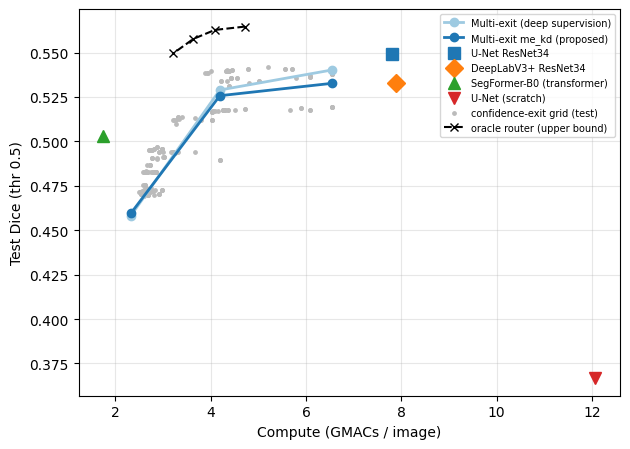

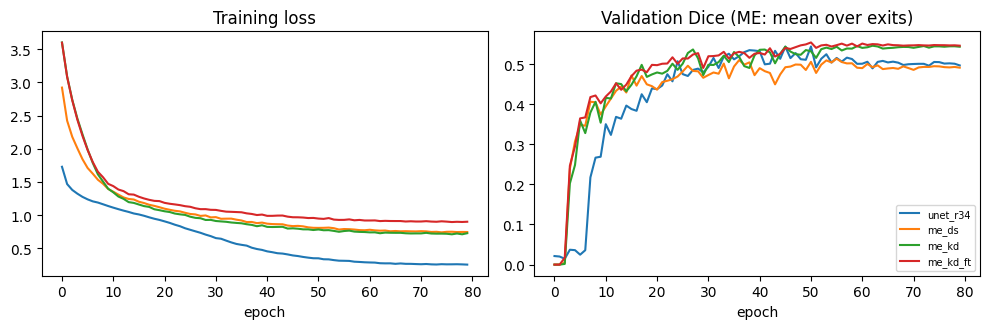

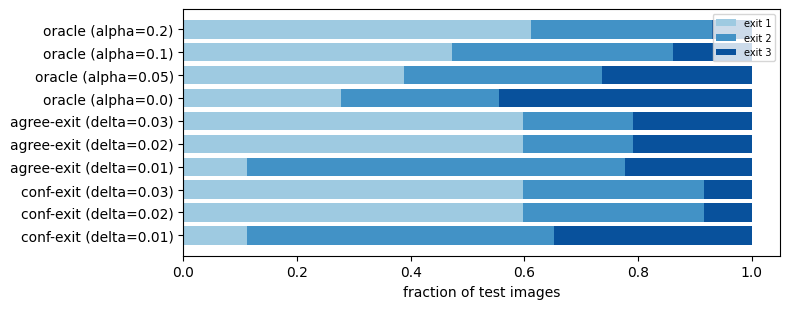

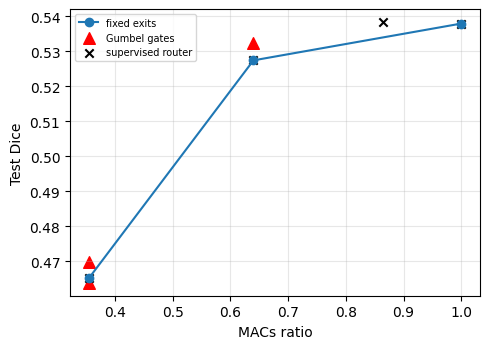

In [21]:
# ---- Fig A: Dice vs GMACs (all models, fixed exits, policies, oracle, chance routing) ----
D = DF[DF.dataset == "FracAtlas"]; fig, ax = plt.subplots(figsize=(6.4, 4.6))
for t, c, lab in [("me_ds", "#9ecae1", "Multi-exit (deep supervision)"), (PROPOSED, "#1f77b4", f"Multi-exit {PROPOSED} (proposed)")]:
    g = D[D.model.str.startswith(t + ":")].groupby("exit")[["gmacs", "dice_thr05"]].mean()
    if len(g): ax.plot(g.gmacs, g.dice_thr05, "o-", color=c, lw=2, label=lab)
for mdl, mk in [("unet_r34", "s"), ("deeplabv3p_r34", "D"), ("segformer_b0", "^"), ("unet_scratch", "v")]:
    g = D[D.model == mdl]
    if len(g): ax.plot(g.gmacs.mean(), g.dice_thr05.mean(), mk, ms=9, label=NAMES[mdl])
pa = [(m_, d_) for s_ in POL.values() for (k_, d_, m_) in s_["pareto"] if k_ == "conf"]
ax.scatter([p[0] * POL[SEEDS[0]]["gmacs_full"] for p in pa], [p[1] for p in pa], s=6, color="#bbb", label="confidence-exit grid (test)")
orc = [p for p in POL[SEEDS[0]]["policies"] if p["name"].startswith("oracle")]
ax.plot([p["macs_ratio"] * POL[SEEDS[0]]["gmacs_full"] for p in orc], [p["dice"] for p in orc], "k--x", label="oracle router (upper bound)")
ax.set_xlabel("Compute (GMACs / image)"); ax.set_ylabel("Test Dice (thr 0.5)"); ax.grid(alpha=.3); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(WORK / "fig_dice_vs_gmacs.png", dpi=200); plt.show()

# ---- Fig B: training curves ----
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for (t, s), h in HIST.items():
    if s != SEEDS[0]: continue
    ax[0].plot(h["train_loss"], label=t); ax[1].plot(h["val_score"], label=t)
ax[0].set_title("Training loss"); ax[1].set_title("Validation Dice (ME: mean over exits)"); ax[0].set_xlabel("epoch"); ax[1].set_xlabel("epoch"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(WORK / "fig_training_curves.png", dpi=200); plt.show()

# ---- Fig C: exit distribution of selected policies ----
pl = [p for p in POL[SEEDS[0]]["policies"] if p["feasible"]]
fig, ax = plt.subplots(figsize=(8, 3.2)); bottom = np.zeros(len(pl))
for k, c in enumerate(["#9ecae1", "#4292c6", "#08519c"]):
    v = np.array([p["exits"][k] for p in pl]); ax.barh([p["name"] for p in pl], v, left=bottom, color=c, label=f"exit {k+1}"); bottom += v
ax.set_xlabel("fraction of test images"); ax.legend(fontsize=7); plt.tight_layout(); plt.savefig(WORK / "fig_exit_distribution.png", dpi=200); plt.show()

# ---- Fig D: FLOPs-vs-Dice trade-off for the Gumbel gates and router (learned routing) ----
if GUM:
    fig, ax = plt.subplots(figsize=(5, 3.6)); Fr0 = POL[SEEDS[0]]["Fr"]; ft = POL[SEEDS[0]]["fixed_test"]
    ax.plot(Fr0, ft, "o-", label="fixed exits"); ax.scatter([g["test"]["macs_ratio"] for g in GUM], [g["test"]["dice"] for g in GUM], marker="^", s=70, color="r", label="Gumbel gates")
    ax.scatter(RT.test_macs, RT.test_dice, marker="x", color="k", label="supervised router"); ax.set_xlabel("MACs ratio"); ax.set_ylabel("Test Dice"); ax.legend(fontsize=7); ax.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(WORK / "fig_learned_routing.png", dpi=200); plt.show()

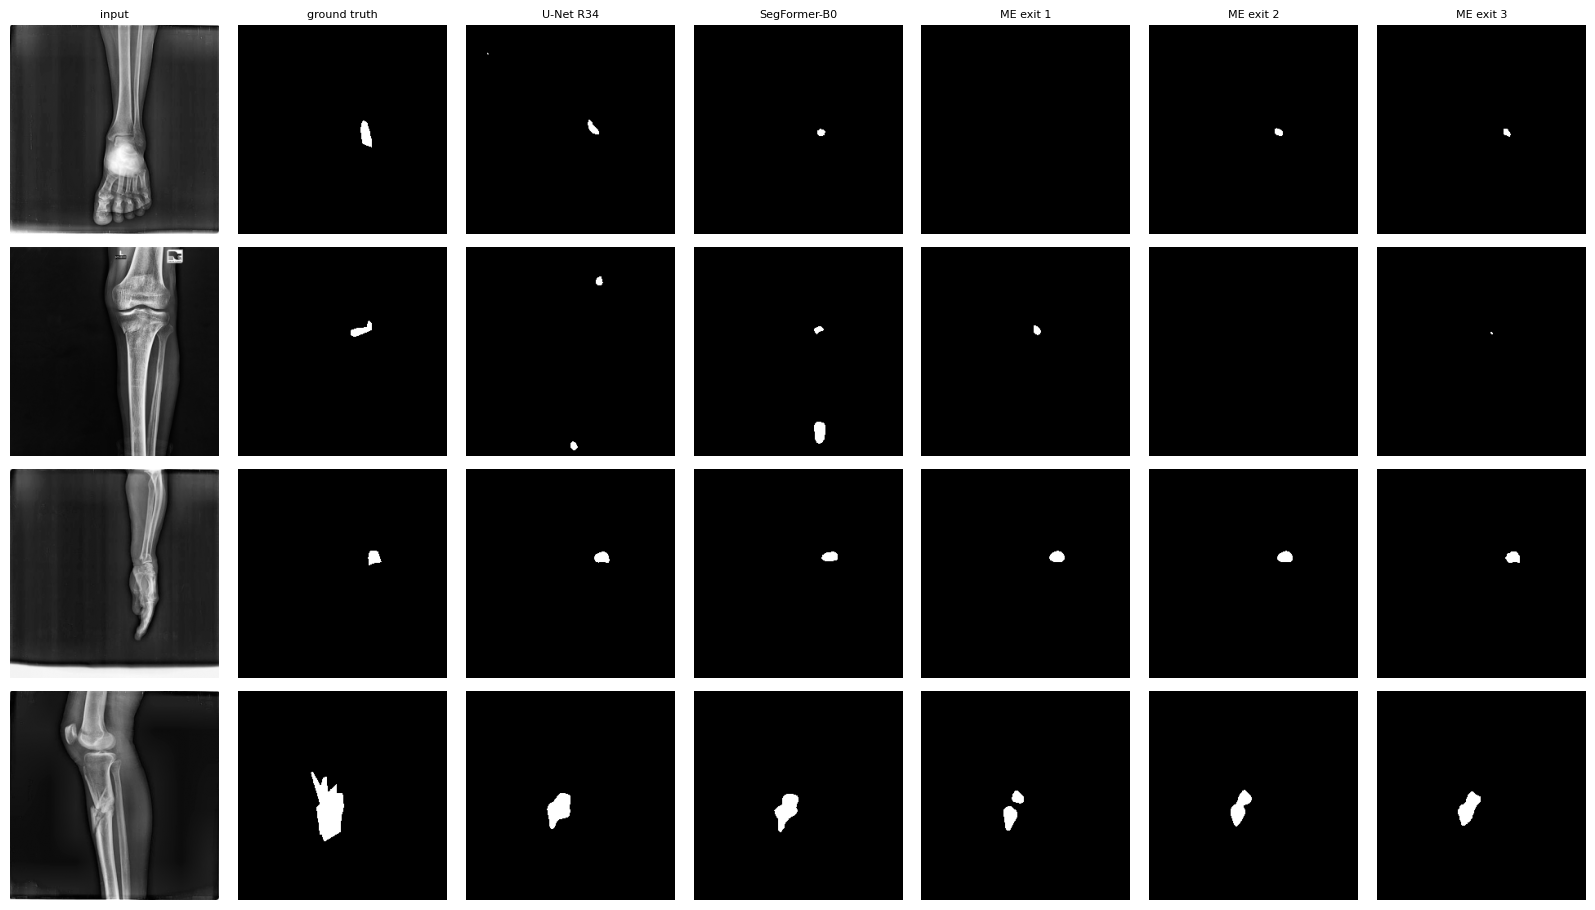

In [22]:
# ---- Fig E: qualitative results (input, ground truth, models, exits) ----
def show_qual(b, seed, tags_models, n=4, fname="fig_qualitative.png"):
    ids = b.split["test"][:n]; cols = [("input", None), ("ground truth", None)]; preds = {}
    for lab, tag, k in tags_models:
        _, tl, _, ty = load_logits(b, tag, seed); preds[lab] = (torch.sigmoid(tl[k]) > 0.5).float()
    fig, axs = plt.subplots(n, 2 + len(preds), figsize=(2.3 * (2 + len(preds)), 2.3 * n))
    for r in range(n):
        im = b.X[ids[r]]; axs[r, 0].imshow(im, cmap="gray" if b.gray else None); axs[r, 1].imshow(b.Y[ids[r]], cmap="gray")
        for c, (lab, pr) in enumerate(preds.items()): axs[r, 2 + c].imshow(pr[r, 0], cmap="gray")
        if r == 0:
            axs[0, 0].set_title("input", fontsize=8); axs[0, 1].set_title("ground truth", fontsize=8)
            for c, lab in enumerate(preds): axs[0, 2 + c].set_title(lab, fontsize=8)
        for a in axs[r]: a.axis("off")
    plt.tight_layout(); plt.savefig(WORK / fname, dpi=200); plt.show()
qm = [("U-Net R34", "unet_r34", 0)]
if RUN_SEGFORMER: qm.append(("SegFormer-B0", "segformer_b0", 0))
qm += [("ME exit 1", PROPOSED, 0), ("ME exit 2", PROPOSED, 1), ("ME exit 3", PROPOSED, 2)]
show_qual(FA, SEEDS[0], qm)

## 13. Summary for the report
Fill the paragraphs below from the tables above (every number must come from this notebook's saved outputs).

| PS2 requirement | Where in this notebook |
|---|---|
| Literature of DyNN / segmentation models | report (not code) |
| Datasets, EDA, preprocessing, augmentation, split | sections 1 |
| Baselines (U-Net, DeepLabV3+, transformer) | sections 4, 6 |
| Proposed DyNN: multi-exit, self-distillation, Gumbel gates, budget loss, router | sections 4, 7, 8 |
| Existing dynamic approach (BranchyNet-style confidence exit) | section 7 |
| Ablations (distillation, loss, gates, uncertainty inputs, thresholds) | sections 6, 7, 8 |
| Dice, IoU, precision, recall, pixel accuracy, HD95 | section 2, final table |
| Params, GMACs, latency, throughput, memory | section 3, final table |
| Class-wise (fracture) performance | binary task: the fracture class *is* the foreground; background IoU is ~1 and uninformative |
| FLOPs-vs-Dice trade-off, exit distribution, qualitative | section 12 |
| Robustness / generalization | section 10 (official split, Kvasir-SEG) |
| Statistical significance | section 9 |